# 05 · Pruebas con MediaPipe (sin reentrenar)

**Objetivo:** comprobar si recortar la mano con MediaPipe mejora el reconocimiento con fotos propias, **usando los modelos ya entrenados** (Baseline, MobileNetV2 y EfficientNetB0). Este notebook solo hace pruebas: no entrena nada y no modifica ningún modelo.

**Qué se hace**
1. **Detección:** en qué porcentaje de fotos propias y de imágenes del dataset MediaPipe encuentra la mano.
2. **Revisión visual:** original frente a recorte, y las fotos donde no detectó nada.
3. **Evaluación:** accuracy de cada modelo con las fotos originales y con las recortadas, en condiciones comparables.

**Cómo está organizado:** MediaPipe corre en un entorno aparte (`.venv-mp`) para no tocar el de TensorFlow. El notebook lo llama como un programa externo, guarda los recortes en `data/mis_fotos_recortes/` y evalúa los modelos aquí, con el kernel de siempre.

> **Antes de empezar:** ejecuta una vez `./setup_mediapipe.sh` en la terminal (crea `.venv-mp` y descarga el modelo de manos).

In [1]:
import os, sys, json, subprocess
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

from src.train import load_config
from src.compare import latest_run, evaluate_on_photos
from src.visualize import list_own_photos

MP_PY = ROOT / ".venv-mp" / "bin" / "python"
MP_MODEL = ROOT / "assets" / "hand_landmarker.task"
FOTOS = ROOT / "data" / "mis_fotos"
RECORTES = ROOT / "data" / "mis_fotos_recortes"
RAW = load_config("configs/baseline.yaml")["data"]["raw_dir"]

assert MP_PY.exists() and MP_MODEL.exists(), "Falta MediaPipe: ejecuta ./setup_mediapipe.sh en la terminal"


def run_mp(*args):
    """Ejecuta src.mediapipe_crop en .venv-mp y muestra su salida."""
    cmd = [str(MP_PY), "-m", "src.mediapipe_crop", "--model", str(MP_MODEL), *map(str, args)]
    r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr[-2000:])
        raise RuntimeError("Falló la ejecución de MediaPipe")


runs = {
    "Baseline": latest_run("baseline"),
    "MobileNetV2": latest_run("mobilenetv2"),
    "EfficientNetB0": latest_run("efficientnetb0"),
}
{k: v.name for k, v in runs.items()}

I0000 00:00:1793935311.189575    3183 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


{'Baseline': '20261024-1217_baseline',
 'MobileNetV2': '20261026-1735_mobilenetv2',
 'EfficientNetB0': '20261026-1751_efficientnetb0'}

## Paso 1a · Detección en las fotos propias
MediaPipe busca una mano en cada foto y se recorta un cuadrado a su alrededor (con un 25 % de margen), guardado a 200×200 como el dataset original. Si no encuentra mano, el recorte es el cuadrado central de la foto y queda marcado como *no detectada*.

Se genera `data/mis_fotos_recortes/` con la misma organización por clase y un archivo `deteccion.csv` con el resultado de cada foto.

In [2]:
run_mp("--input", FOTOS, "--output", RECORTES, "--csv", RECORTES / "deteccion.csv")

det = pd.read_csv(RECORTES / "deteccion.csv")
print(f"Detección global en fotos propias: {det.detected.mean():.1%} ({det.detected.sum()} de {len(det)})")
display(det.groupby("label").detected.agg(tasa="mean", fotos="count").sort_values("tasa").round(2))

  200/460 imágenes (14.4 img/s)
  400/460 imágenes (14.7 img/s)
460 imágenes | mano detectada en 405 (88.0%) | 31 s (14.8 img/s)

Detección global en fotos propias: 88.0% (405 de 460)


,tasa,fotos
label,,
nothing,0.00,15
del,0.53,15
N,0.73,15
H,0.80,15
E,0.80,15
Q,0.80,15
M,0.86,14
G,0.87,15
R,0.87,15


> Si la tasa es baja, se puede relajar la exigencia de MediaPipe añadiendo `"--min-conf", 0.3` a la llamada de arriba y volver a ejecutar. Si siguen sin detectarse muchas, la idea del recorte no es viable con estas fotos tal como están.

## Paso 1b · Detección en una muestra del dataset
Mismo análisis con 50 imágenes por clase del dataset original (1.450 en total), solo midiendo la detección, sin guardar recortes. Sirve para saber si MediaPipe funciona igual de bien con las imágenes de 200×200 del dataset y para ver cuánto tardaría procesarlo entero. En la clase `nothing` (sin mano) se espera una tasa cercana a 0.

In [3]:
run_mp("--input", RAW, "--csv", ROOT / "data" / "deteccion_dataset.csv", "--max-per-class", 500)

det_ds = pd.read_csv(ROOT / "data" / "deteccion_dataset.csv")
comparacion = pd.DataFrame({
    "dataset": det_ds.groupby("label").detected.mean(),
    "fotos propias": det.groupby("label").detected.mean(),
}).round(2)
print(f"Detección global en el dataset: {det_ds.detected.mean():.1%}")
display(comparacion.sort_values("dataset"))

  200/14500 imágenes (55.6 img/s)
  400/14500 imágenes (58.7 img/s)
  600/14500 imágenes (58.3 img/s)
  800/14500 imágenes (58.0 img/s)
  1000/14500 imágenes (58.5 img/s)
  1200/14500 imágenes (57.4 img/s)
  1400/14500 imágenes (58.4 img/s)
  1600/14500 imágenes (57.8 img/s)
  1800/14500 imágenes (57.3 img/s)
  2000/14500 imágenes (57.5 img/s)
  2200/14500 imágenes (57.1 img/s)
  2400/14500 imágenes (57.5 img/s)
  2600/14500 imágenes (56.9 img/s)
  2800/14500 imágenes (56.5 img/s)
  3000/14500 imágenes (56.1 img/s)
  3200/14500 imágenes (56.0 img/s)
  3400/14500 imágenes (56.1 img/s)
  3600/14500 imágenes (56.1 img/s)
  3800/14500 imágenes (56.0 img/s)
  4000/14500 imágenes (56.1 img/s)
  4200/14500 imágenes (55.9 img/s)
  4400/14500 imágenes (56.2 img/s)
  4600/14500 imágenes (56.0 img/s)
  4800/14500 imágenes (55.9 img/s)
  5000/14500 imágenes (55.8 img/s)
  5200/14500 imágenes (55.5 img/s)
  5400/14500 imágenes (55.5 img/s)
  5600/14500 imágenes (55.5 img/s)
  5800/14500 imágenes (5

,dataset,fotos propias
label,,
nothing,0.00,0.00
N,0.42,0.73
M,0.54,0.86
space,0.55,0.90
del,0.60,0.53
Q,0.66,0.80
C,0.66,0.88
P,0.69,0.88
X,0.71,1.00


## Paso 2 · Revisión visual
Arriba, la foto original; abajo, el recorte. Comprueba que la mano queda completa, centrada y que el recorte no corta dedos. Después se listan las fotos donde no hubo detección.

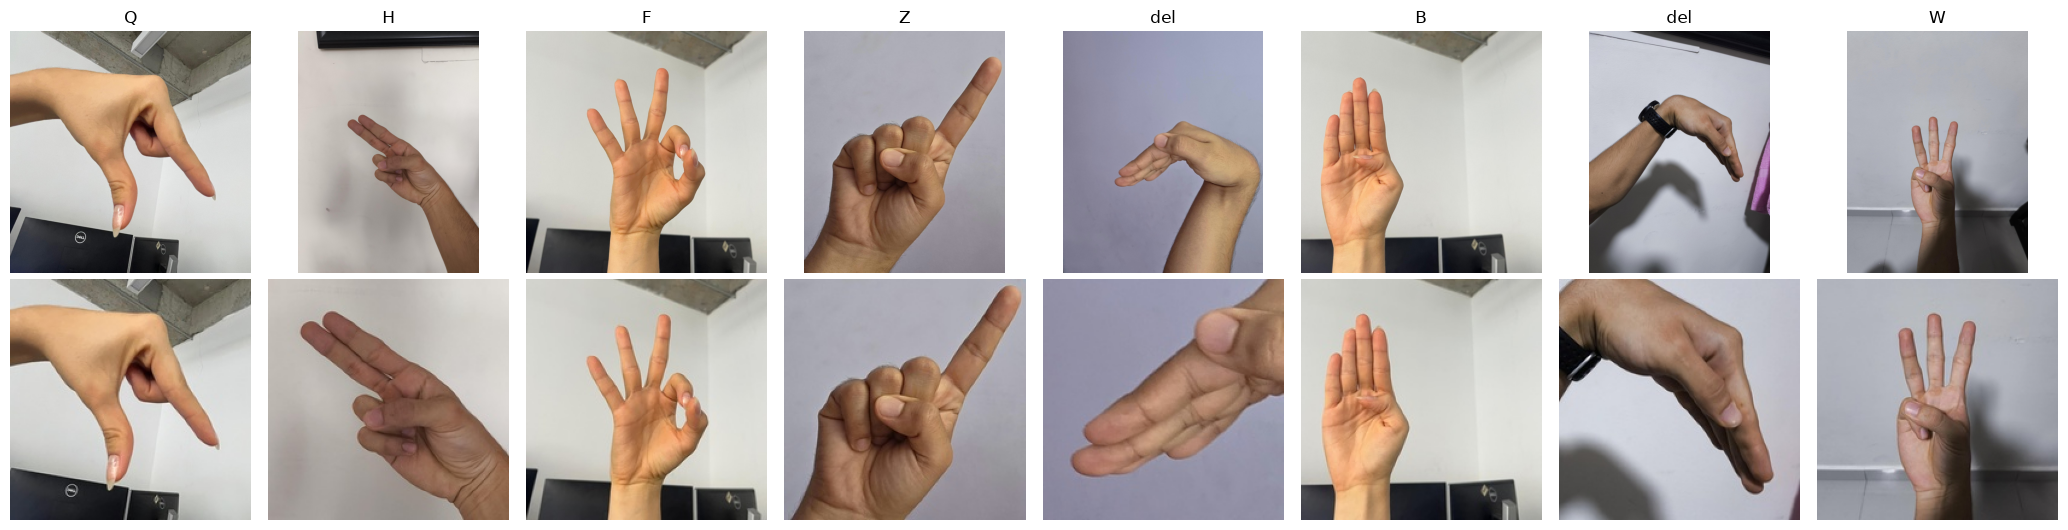

55 fotos sin mano detectada


,path
9,A/A_10.jpg
31,C/C_01.jpg
46,C/C_99.jpg
55,D/D_09.jpg
67,E/E_06.jpg
68,E/E_07.jpg
71,E/E_10.jpg
84,F/F_08.jpg
100,G/G_09.jpg
101,G/G_10.jpg


In [16]:
muestra = det[det.detected].sample(min(8, int(det.detected.sum())), random_state=7)
fig, axes = plt.subplots(2, len(muestra), figsize=(2.6 * len(muestra), 5.4), squeeze=False)
for j, r in enumerate(muestra.itertuples()):
    axes[0, j].imshow(ImageOps.exif_transpose(Image.open(FOTOS / r.path)).convert("RGB"))
    axes[1, j].imshow(Image.open(RECORTES / r.path))
    axes[0, j].set_title(r.label)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

sin_mano = det[~det.detected]
print(f"{len(sin_mano)} fotos sin mano detectada")
display(sin_mano[["path"]].head(30))

## Paso 3 · Evaluar los modelos actuales con fotos originales y recortadas
Los modelos **no se reentrenan**: se evalúan tal como están. Para que la comparación sea justa se usan cuatro conjuntos:

| Conjunto | Fotos | Para qué sirve |
|---|---|---|
| **A** · originales (todas) | todas | Punto de control: debe reproducir los resultados del notebook 04 (22,6 %, 52,2 % y 58,0 %) |
| **B** · originales (solo con mano detectada) | solo las detectadas | Referencia sin sesgo de selección |
| **C** · recortadas (solo con mano detectada) | las mismas fotos que B | **Efecto puro del recorte** (compara B contra C) |
| **D** · recortadas (todas) | todas, las no detectadas con recorte central | Resultado de un pipeline real con respaldo |

La comparación importante es **B frente a C**: mismas fotos, solo cambia el recorte.

In [5]:
class_names = json.loads((runs["Baseline"] / "final" / "classes.json").read_text())

orig = list_own_photos(FOTOS, class_names)
crop = list_own_photos(RECORTES, class_names)

rel = lambda p, base: str(Path(p).relative_to(base))
detectadas = set(det[det.detected].path)
orig_ok = orig[orig.path.map(lambda p: rel(p, FOTOS)).isin(detectadas)].reset_index(drop=True)
crop_ok = crop[crop.path.map(lambda p: rel(p, RECORTES)).isin(detectadas)].reset_index(drop=True)
print(f"Fotos: {len(orig)} en total | {len(orig_ok)} con mano detectada")

A, B, C, D = ("A · originales (todas)", "B · originales (solo detectadas)",
              "C · recortadas (solo detectadas)", "D · recortadas (todas)")
conjuntos = {A: orig, B: orig_ok, C: crop_ok, D: crop}

tablas, detalles = {}, {}
for nombre, df_ in conjuntos.items():
    t, d = evaluate_on_photos(runs, df_)
    tablas[nombre], detalles[nombre] = t["accuracy fotos propias"], d

resumen = pd.DataFrame(tablas).T
display((resumen * 100).round(1))

Fotos: 460 en total | 405 con mano detectada


I0000 00:00:1793935602.695102    3183 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:10:00.0, compute capability: 8.9
/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 58 variables whereas the saved optimizer has 62 variables. 
  saveable.load_own_variables(store)
I0000 00:00:1793935614.540787    4297 cuda_dnn.cc:461] Loaded cuDNN version 92700
/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 26 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)
/home/juan/proyectos/asl-sign-language-recognition/.venv/lib/python3.12/site-packages/keras

,Baseline,MobileNetV2,EfficientNetB0
A · originales (todas),22.6,52.2,58.0
B · originales (solo detectadas),20.7,50.9,57.3
C · recortadas (solo detectadas),17.5,51.1,55.3
D · recortadas (todas),19.8,52.2,56.5


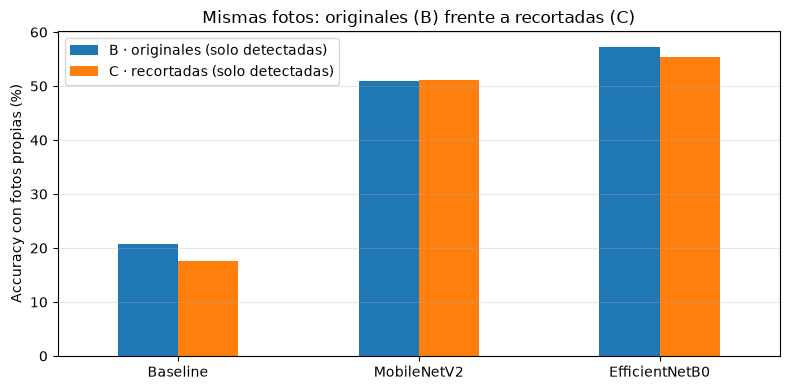

Cambio por el recorte (C - B), en puntos porcentuales:
Baseline         -3.2
MobileNetV2       0.2
EfficientNetB0   -2.0


In [6]:
ax = (resumen.loc[[B, C]].T * 100).plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("Accuracy con fotos propias (%)")
ax.set_title("Mismas fotos: originales (B) frente a recortadas (C)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Cambio por el recorte (C - B), en puntos porcentuales:")
print(((resumen.loc[C] - resumen.loc[B]) * 100).round(1).to_string())

## Paso 4 · ¿Qué letras cambian?
Para un modelo concreto, accuracy por letra con las fotos originales y con las recortadas (solo las fotos detectadas), ordenado de la letra que más empeora a la que más mejora. Cambia `modelo` para ver otro.

In [7]:
modelo = "EfficientNetB0"   # "Baseline" / "MobileNetV2" / "EfficientNetB0"

por_letra = pd.DataFrame({
    "originales": detalles[B][modelo].groupby("label").correct.mean(),
    "recortadas": detalles[C][modelo].groupby("label").correct.mean(),
    "fotos": detalles[B][modelo].groupby("label").size(),
})
por_letra["cambio"] = por_letra.recortadas - por_letra.originales
display(por_letra.sort_values("cambio").round(2))

,originales,recortadas,fotos,cambio
label,,,,
del,1.00,0.25,8,-0.75
B,0.75,0.44,16,-0.31
K,0.27,0.07,15,-0.20
R,0.77,0.69,13,-0.08
I,0.50,0.43,14,-0.07
J,0.14,0.07,14,-0.07
L,0.13,0.07,15,-0.07
Z,0.60,0.53,15,-0.07
W,1.00,0.95,20,-0.05


## Pruebas para evaluar el rendimiento

#### Celda 1 · Original frente a recorte, del y B

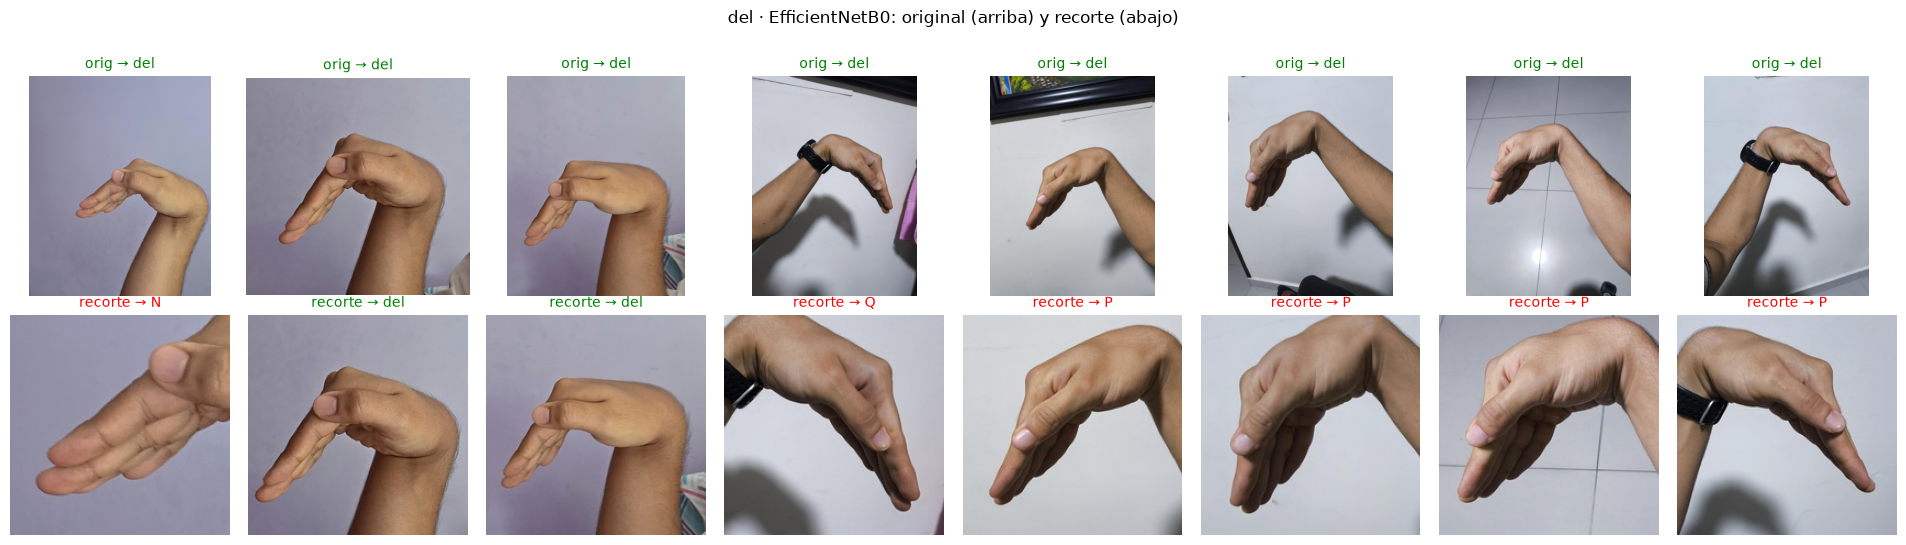

Mostradas 8 fotos | acierto original 100% → recorte 25%


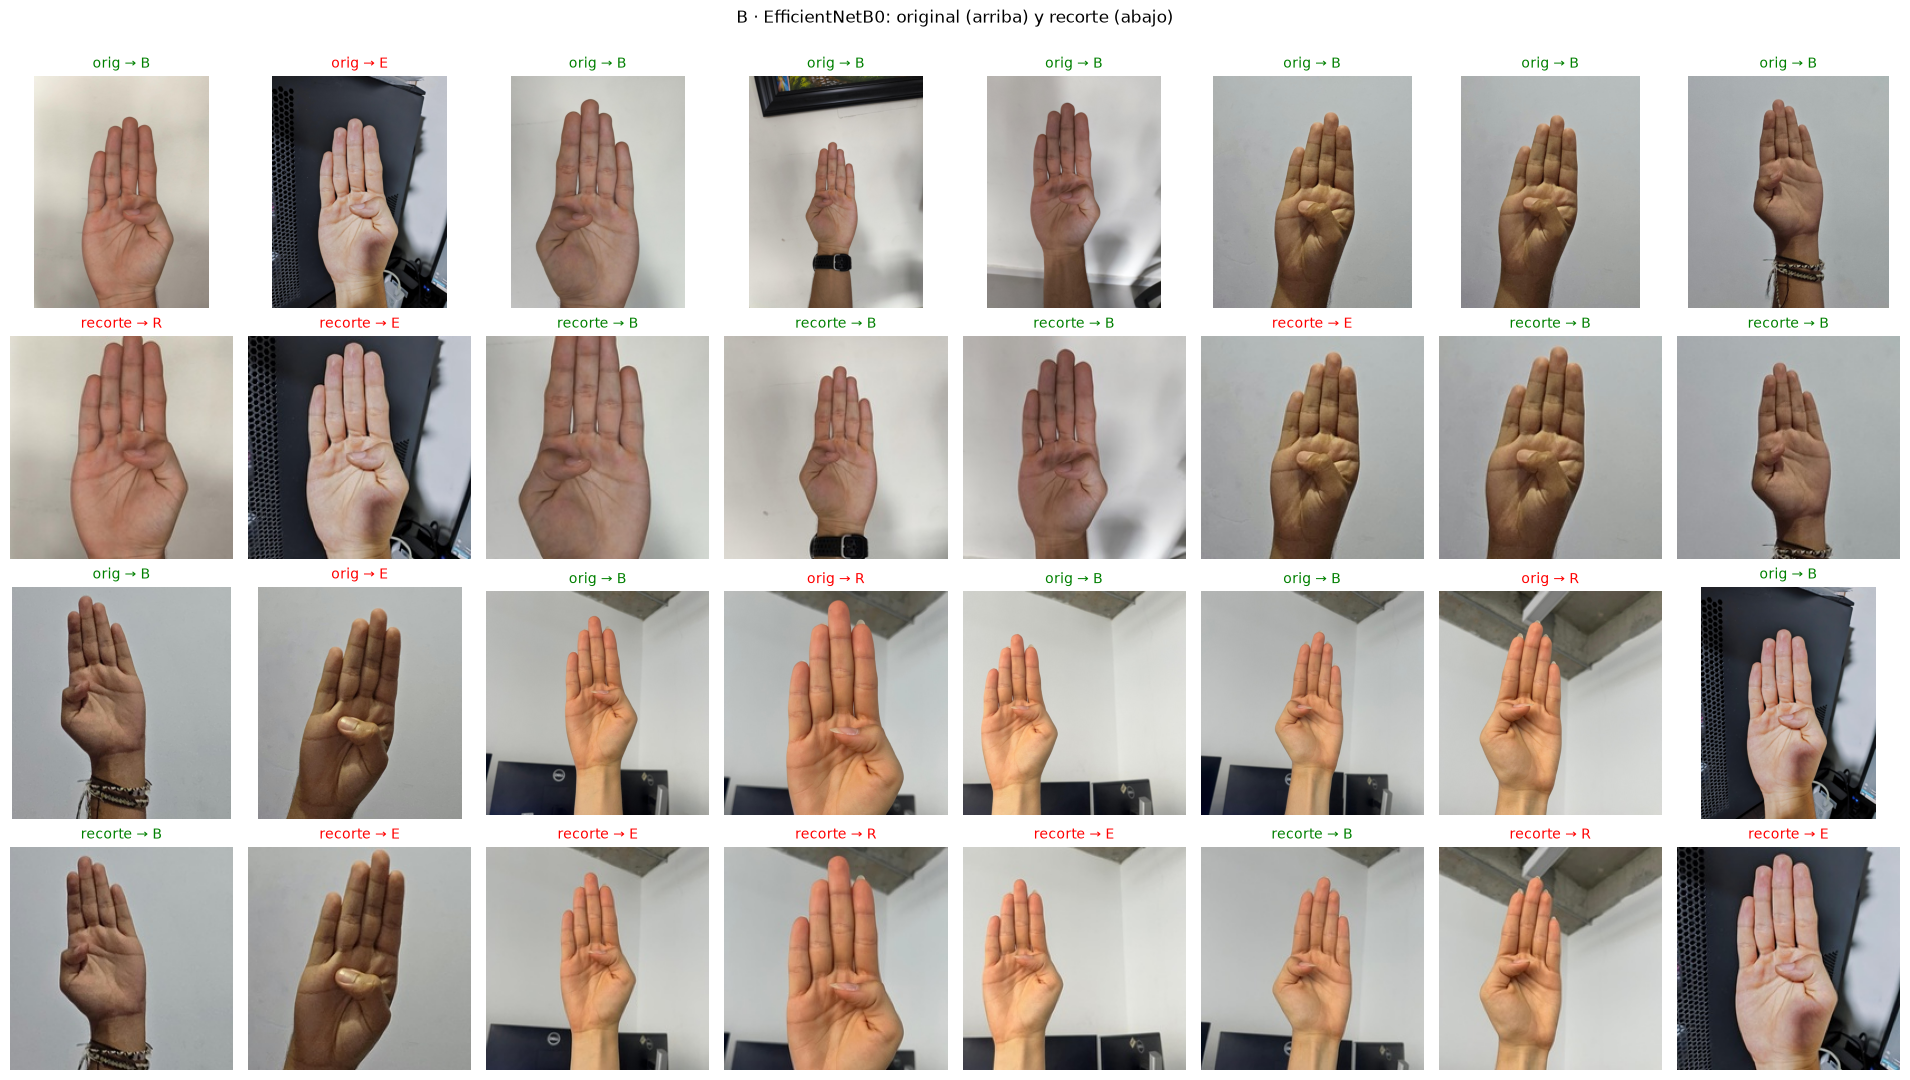

Mostradas 16 fotos | acierto original 75% → recorte 44%


In [17]:
from math import ceil

def ver_letra(letra, modelo="EfficientNetB0", max_fotos=16, cols=8):
    """Arriba la foto original, abajo su recorte. El título es la predicción del modelo
    (verde = acierto, rojo = error)."""
    po = {rel(r.path, FOTOS): r for r in detalles[B][modelo].itertuples()}
    pc = {rel(r.path, RECORTES): r for r in detalles[C][modelo].itertuples()}
    filas = det[(det.label == letra) & det.detected].head(max_fotos)
    bloques = ceil(len(filas) / cols)
    fig, axes = plt.subplots(2 * bloques, cols, figsize=(2.4 * cols, 5.4 * bloques), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for k, r in enumerate(filas.itertuples()):
        b, j = divmod(k, cols)
        for fila, (nombre, img, pred) in enumerate((
            ("orig", ImageOps.exif_transpose(Image.open(FOTOS / r.path)).convert("RGB"), po.get(r.path)),
            ("recorte", Image.open(RECORTES / r.path), pc.get(r.path)),
        )):
            ax = axes[2 * b + fila, j]
            ax.imshow(img)
            if pred is not None:
                ax.set_title(f"{nombre} → {pred.pred}", fontsize=10, color="green" if pred.correct else "red")
    fig.suptitle(f"{letra} · {modelo}: original (arriba) y recorte (abajo)", y=1.0)
    plt.tight_layout()
    plt.show()
    o = detalles[B][modelo]; o = o[(o.label == letra) & o.path.map(lambda p: rel(p, FOTOS)).isin(filas.path)]
    c = detalles[C][modelo]; c = c[(c.label == letra) & c.path.map(lambda p: rel(p, RECORTES)).isin(filas.path)]
    print(f"Mostradas {len(filas)} fotos | acierto original {o.correct.mean():.0%} → recorte {c.correct.mean():.0%}")

ver_letra("del")
ver_letra("B")

#### Celda 2 · Fotos sin detección de N, E, H y Q

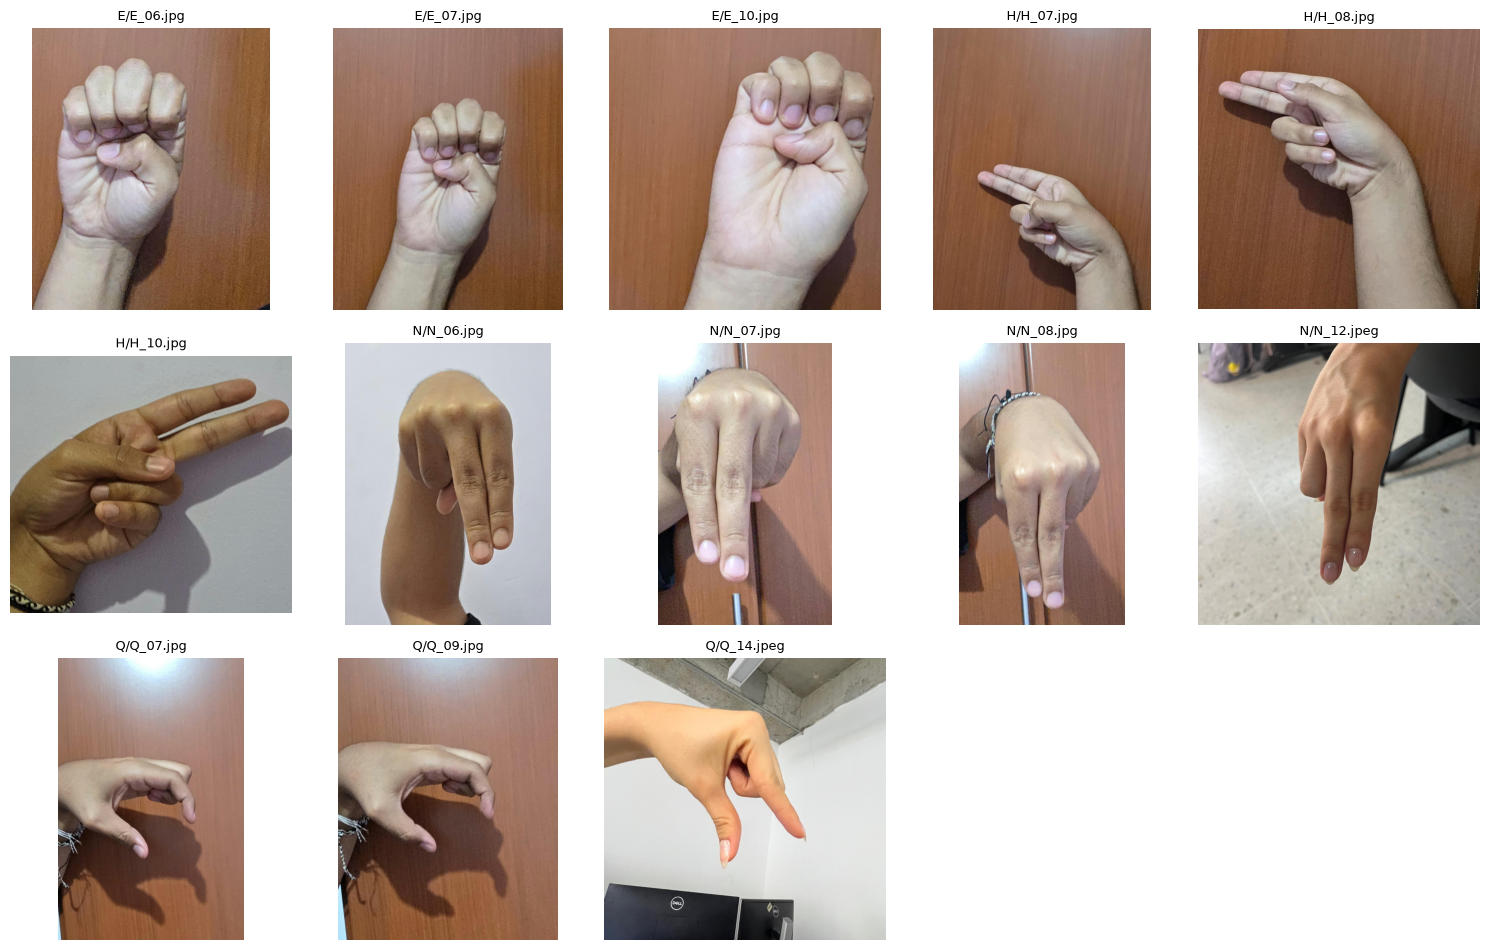

13 fotos sin detección


In [18]:
letras = ["N", "E", "H", "Q"]
sin = det[(~det.detected) & det.label.isin(letras)]
cols = 5
filas_n = ceil(len(sin) / cols)
fig, axes = plt.subplots(filas_n, cols, figsize=(3 * cols, 3.2 * filas_n), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, r in zip(axes.flat, sin.itertuples()):
    ax.imshow(ImageOps.exif_transpose(Image.open(FOTOS / r.path)).convert("RGB"))
    ax.set_title(r.path, fontsize=9)
plt.tight_layout()
plt.show()
print(f"{len(sin)} fotos sin detección")

#### Celda 3 (opcional) · ¿Recupera fotos bajar la exigencia?

In [19]:
run_mp("--input", FOTOS, "--csv", ROOT / "data" / "deteccion_conf03.csv", "--min-conf", 0.3)
det03 = pd.read_csv(ROOT / "data" / "deteccion_conf03.csv")
m = det.merge(det03[["path", "detected"]], on="path", suffixes=("", "_03"))
nuevas = m[~m.detected & m.detected_03]
print(f"Con confianza 0,3: {det03.detected.mean():.1%} (antes {det.detected.mean():.1%}) | {len(nuevas)} fotos recuperadas")
display(nuevas.groupby("label").size().rename("fotos recuperadas"))

  200/460 imágenes (17.9 img/s)
  400/460 imágenes (18.0 img/s)
460 imágenes | mano detectada en 411 (89.3%) | 26 s (18.0 img/s)

Con confianza 0,3: 89.3% (antes 88.0%) | 6 fotos recuperadas


label
J      1
Q      1
R      1
S      1
del    2
Name: fotos recuperadas, dtype: int64

### Conclusiones Clave del Experimento

* **Inviabilidad del recorte con MediaPipe:** El modelo no vale la pena ser reentrenado con este tipo de recorte en su estado actual; los resultados numéricos se deben a que se **pierde el contexto del brazo** y se **altera la escala** de la imagen.
* **Sensibilidad a la escala:** Los modelos muestran una alta sensibilidad al tamaño de la mano, una variabilidad que el aumento de datos actual (zoom de ±10%) **no logra cubrir** adecuadamente.
* **Complejidad del entorno:** La sesión grabada con el fondo de madera representa uno de los escenarios más difíciles para el modelo, aunque con el conjunto de datos disponible **no es posible medir con precisión** el impacto exacto de este factor.
